# G4P5 — Congelamiento de la fracción de neutrones

Usamos $x=Q/T$, con $k_B=1$, $H(x)=H_1/x^2$ y $g_*=10.75$ constante.
La aproximación incluye capturas débiles, pero no el decaimiento libre tardío
del neutrón ni su captura en núcleos. La meseta final representa congelamiento,
no la abundancia final de una red BBN completa.

## Importaciones y parámetros
Se conserva el valor original de la vida media: 887.7 s.

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
from matplotlib import pyplot as plt

tau_n =887.7  # s; se conserva el valor del enunciado original
H_1 = 1.13  # s^-1; H a T = Q, para Q ~ 1.293 MeV y g_* = 10.75
xi = 1.0e-2
xf = 1.0e3

## Tasas y ecuación de evolución

$$\lambda_{np}(x)=\frac{255}{\tau_n x^5}(12+6x+x^2),
\qquad \lambda_{pn}=e^{-x}\lambda_{np}.$$

$$\frac{dX_n}{dx}=\frac{x\lambda_{np}}{H_1}
\left[e^{-x}-(1+e^{-x})X_n\right],
\qquad X_n^{\rm eq}=\frac{e^{-x}}{1+e^{-x}}.$$

Aquí $X_n=n_n/(n_n+n_p)$; por tanto $n_n/n_p=X_n/(1-X_n)$.

In [ ]:
def lambda_np(x):
    """Tasa aproximada de conversión n -> p por capturas débiles, en s^-1."""
    return 255.0 / (tau_n * x**5) * (12.0 + 6.0*x + x**2)


def Xn_equilibrio(x):
    """Xn de equilibrio; esta forma evita desbordar exp(x) a x grande."""
    exp_menos_x = np.exp(-x)
    return exp_menos_x / (1.0 + exp_menos_x)


def dXn_dx(x, y):
    """Evolución: dXn/dt = lambda_pn*(1-Xn) - lambda_np*Xn.

    Como dx/dt = H*x = H_1/x, dt/dx = x/H_1.
    """
    exp_menos_x = np.exp(-x)
    return (x * lambda_np(x) / H_1) * (exp_menos_x - y*(1 + exp_menos_x))

## ¿Dónde entra el decaimiento del neutrón?

El proceso de decaimiento libre es
$$n\longrightarrow p+e^-+\bar\nu_e.$$
En este notebook hay que distinguir **dos papeles de la vida media**
$\tau_n=887.7\,\mathrm{s}$:

**1. Normalización de las tasas débiles (sí está incluida).**
La función `lambda_np(x)` contiene el factor $255/\tau_n$. La vida media
medida fija la intensidad de la interacción débil usada para aproximar las
capturas $n+\nu_e\to p+e^-$ y $n+e^+\to p+\bar\nu_e$.
Usar $\tau_n$ en ese prefactor **no añade por sí solo la pérdida de neutrones
por decaimiento libre**. En particular, la tasa implementada satisface
$$\lambda_{np}(x)\sim\frac{255}{\tau_n x^3}\longrightarrow0
\quad (x\longrightarrow\infty),$$
mientras que la tasa de decaimiento de un neutrón libre a baja temperatura
tiende a $1/\tau_n$, no a cero.

**2. Pérdida explícita por decaimiento libre (no está incluida).**
En el régimen tardío, cuando pueden despreciarse el proceso inverso y el
bloqueo estadístico de los productos, el decaimiento aporta
$$\left.\frac{dX_n}{dt}\right|_{\rm decay}=-\frac{X_n}{\tau_n}.$$
Como aquí $dt/dx=x/H_1$, su contribución sería
$$\boxed{\left.\frac{dX_n}{dx}\right|_{\rm decay}
=-\frac{x}{H_1\tau_n}X_n.}$$
Por tanto, una extensión aproximada de la ecuación implementada sería
$$\frac{dX_n}{dx}=\frac{x\lambda_{np}}{H_1}
\left[e^{-x}-(1+e^{-x})X_n\right]
-\frac{x}{H_1\tau_n}X_n.$$
En Python, el término adicional en `dXn_dx` sería `-x*y/(H_1*tau_n)`.
**Se muestra para explicar la física; no se ha añadido a las celdas de cálculo.**
No basta con añadirlo a todo régimen para obtener tasas de precisión:
a temperaturas altas también deben tratarse el decaimiento inverso y los
factores estadísticos de los electrones y neutrinos. Tampoco se debe añadir
por separado si se usa una tasa completa que ya incluye el decaimiento.

**Cómo interpretar los gráficos actuales.**
La meseta de $X_n$ aparece porque las capturas dejan de ser eficientes y la
ecuación actual no tiene el término de decaimiento libre. Si solo quedara
ese decaimiento después de un punto $x_f$, dentro de la misma aproximación
$H=H_1/x^2$ se obtendría
$$X_n(x)=X_n(x_f)\exp\left[-\frac{x^2-x_f^2}{2H_1\tau_n}\right].$$
Aquí $x_f$ designa un punto elegido después del congelamiento, no la variable
`xf` que fija el extremo de integración del código. En la BBN real, muchos
neutrones terminan ligados en núcleos; esta ecuación de neutrones libres no
describe ese proceso ni determina por sí sola la abundancia final de helio.


## Solución numérica
Partimos del equilibrio térmico y usamos Radau para resolver la ecuación rígida.

### Condiciones iniciales

La variable independiente es $x=Q/T$, con $k_B=1$. Elegimos
`xi = 0.01`, de modo que $T_i=Q/x_i=100Q$: el cálculo comienza
mucho antes del congelamiento, cuando las conversiones débiles son rápidas
comparadas con la expansión. En esa situación la fracción de neutrones
sigue aproximadamente su valor de equilibrio térmico.

Despreciando los potenciales químicos de los leptones y la pequeña diferencia
de masas en los prefactores estadísticos, el balance detallado da
$$\frac{n_n}{n_p}=e^{-Q/T}=e^{-x}.$$
Por tanto, la condición inicial es
$$X_n(x_i)=\frac{n_n}{n_n+n_p}
=\frac{1}{1+e^{x_i}}
=\frac{e^{-x_i}}{1+e^{-x_i}}
\simeq 0.49750002.$$
Esto es lo que representa `CI = [Xn_equilibrio(xi)]`. La lista tiene un solo
elemento porque se integra una sola ecuación diferencial. A temperaturas
muy altas, $x\ll1$ y $X_n\to1/2$: hay casi tantos neutrones como protones.
No se debe confundir $X_n$ con la razón inicial $n_n/n_p\simeq0.99005$.

El punto inicial es una elección numérica dentro de este modelo simplificado.
Para $Q\simeq1.293\,\mathrm{MeV}$ corresponde formalmente a
$T_i\simeq129.3\,\mathrm{MeV}$, donde prolongar las hipótesis de composición
y $g_*=10.75$ constante no describe con precisión el plasma real. Su función
aquí es iniciar la solución en equilibrio; puede comprobarse que el resultado
de congelamiento sea estable al comenzar en otro punto suficientemente
anterior a este. Si se cambia `xi`, hay que recalcular también `CI`.

`xf = 1000` fija únicamente el extremo final de integración; **no es una
segunda condición inicial ni una condición de contorno**. Como se explica
arriba, la evolución a valores grandes de $x$ omite el decaimiento libre
tardío y la formación de núcleos.


In [ ]:
CI =[Xn_equilibrio(xi)]  # condición inicial en equilibrio térmico


def resolver():
    """Integra desde xi hasta xf usando un método para ecuaciones rígidas."""
    sol = solve_ivp(
        dXn_dx,
        [xi, xf],
        CI,
        t_eval=np.geomspace(xi, xf, 300),
        method='Radau',
        rtol=1.0e-8,
        atol=1.0e-10,
    )
    if not sol.success:
        raise RuntimeError(f'Falló la integración: {sol.message}')
    return sol

sol = resolver()
Xn = sol.y[0]
nn_np = Xn / (1.0 - Xn)

print(f'Xn(x={xf:g}) = {Xn[-1]:.6f}')
print(f'n_n/n_p(x={xf:g}) = {nn_np[-1]:.6f}')

Xn(x=1000) = 0.148096
n_n/n_p(x=1000) = 0.173841


## Razón de neutrones a protones

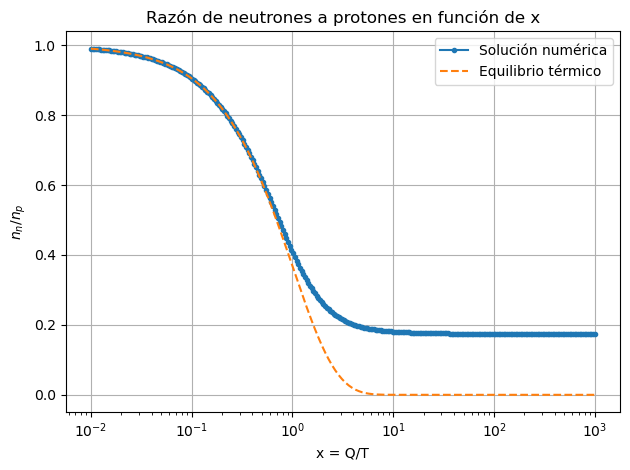

In [ ]:
plt.figure()
plt.title('Razón de neutrones a protones en función de x')
plt.xlabel('x = Q/T')
plt.ylabel(r'$n_n/n_p$')
plt.semilogx(sol.t, nn_np, '.-', label='Solución numérica')
plt.semilogx(sol.t, np.exp(-sol.t), '--', label='Equilibrio térmico')
plt.grid()
# plt.yscale('log')
plt.legend(loc='best')
plt.tight_layout()
plt.show()

## Fracción de neutrones

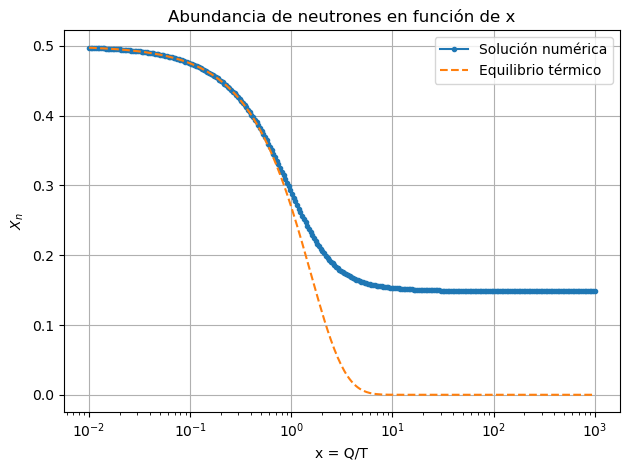

In [ ]:
plt.figure()
plt.title('Abundancia de neutrones en función de x')
plt.xlabel('x = Q/T')
plt.ylabel(r'$X_n$')
plt.semilogx(sol.t, Xn, '.-', label='Solución numérica')
plt.semilogx(sol.t, Xn_equilibrio(sol.t), '--', label='Equilibrio térmico')
plt.grid()
plt.legend(loc='best')
plt.tight_layout()
plt.show()